# Regularization and Dropout — Assignment 4

Original regularization tutorial structure retained. This version uses the **UCI Raisin** dataset (seven numerical features; two classes) and compares L2, L1, dropout, and data augmentation with training/validation accuracy. The held-out test set is used only after model selection.

## Contents

1. Packages and data  
2. Original regularization tutorial (baseline, L2, dropout)  
3. L1, L2, dropout and augmentation sweeps  
4. Comparative results and final test  
5. Discussion

<a name='1'></a>
## 1 - Packages

In [1]:
# download the auxiliary scripts from the public repository.
import os, sys, subprocess
from pathlib import Path
BASE = "https://raw.githubusercontent.com/agrptec/assignment4-raisin-regularization/main/scripts"
Path("scripts").mkdir(exist_ok=True)
for name in ("reg_utils.py", "testCases.py", "public_tests.py"):
    subprocess.run(["wget", "-q", "-O", f"scripts/{name}", f"{BASE}/{name}"], check=True)
sys.path.insert(0, str(Path("scripts").resolve()))
%pip -q install ucimlrepo
%pip install -q dlai-tools

In [2]:
# import packages
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import sklearn.datasets
import scipy.io
from reg_utils import sigmoid, relu, plot_decision_boundary, plot_decision_boundary_pca, initialize_parameters, load_2D_dataset, predict_dec
from reg_utils import compute_cost, predict, forward_propagation, backward_propagation, update_parameters
from testCases import *
from public_tests import *

%matplotlib inline
plt.rcParams['figure.figsize'] = (7.0, 4.0) # set default size of plots
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'


In [3]:
# repairing a numpy incompatibility
if not hasattr(np, 'int'):
    np.int = int


<a name='2'></a>
## 2 - Problem Statement

Raisin (UCI): classify Kecimen vs Besni using seven morphological features.


<a name='3'></a>
## 3 - Loading the Dataset

In [4]:
# UCI Raisin dataset binary classification
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
raisin = fetch_ucirepo(id=850)
X = raisin.data.features.to_numpy(dtype=float)
y = raisin.data.targets.iloc[:, 0].map({"Kecimen": 0, "Besni": 1}).to_numpy(dtype=int)
assert np.isfinite(X).all() and not np.isnan(y).any()
Xtr, Xtmp, ytr, ytmp = train_test_split(X, y, test_size=0.4, stratify=y, random_state=42)
Xval, Xte, yval, yte = train_test_split(Xtmp, ytmp, test_size=0.5, stratify=ytmp, random_state=42)
scaler = StandardScaler()
train_X, train_Y = scaler.fit_transform(Xtr).T, ytr.reshape(1, -1)
val_X, val_Y = scaler.transform(Xval).T, yval.reshape(1, -1)
test_X, test_Y = scaler.transform(Xte).T, yte.reshape(1, -1)
print("Train / validation / test:", train_X.shape, val_X.shape, test_X.shape)


Train / validation / test: (7, 540) (7, 180) (7, 180)


The input has seven standardized features; the model performs binary classification.


The dataset is divided into stratified training, validation and held-out test sets.


<a name='4'></a>
## 4 - Non-Regularized Model

You will use the following neural network (already implemented for you below). This model can be used:
- in *regularization mode* -- by setting the `lambd` input to a non-zero value. We use "`lambd`" instead of "`lambda`" because "`lambda`" is a reserved keyword in Python.
- in *dropout mode* -- by setting the `keep_prob` to a value less than one

You will first try the model without any regularization. Then, you will implement:
- *L2 regularization* -- functions: "`compute_cost_with_regularization()`" and "`backward_propagation_with_regularization()`"
- *Dropout* -- functions: "`forward_propagation_with_dropout()`" and "`backward_propagation_with_dropout()`"

In each part, you will run this model with the correct inputs so that it calls the functions you've implemented. Take a look at the code below to familiarize yourself with the model.

In [5]:
def model(X, Y, learning_rate = 0.3, num_iterations = 30000, print_cost = True, lambd = 0, keep_prob = 1):
    """
    Implements a three-layer neural network: LINEAR->RELU->LINEAR->RELU->LINEAR->SIGMOID.

    Arguments:
    X -- input data, of shape (input size, number of examples)
    Y -- true "label" vector (1 for blue dot / 0 for red dot), of shape (output size, number of examples)
    learning_rate -- learning rate of the optimization
    num_iterations -- number of iterations of the optimization loop
    print_cost -- If True, print the cost every 10000 iterations
    lambd -- regularization hyperparameter, scalar
    keep_prob - probability of keeping a neuron active during drop-out, scalar.

    Returns:
    parameters -- parameters learned by the model. They can then be used to predict.
    """

    grads = {}
    costs = []                            # to keep track of the cost
    m = X.shape[1]                        # number of examples
    layers_dims = [X.shape[0], 20, 3, 1]

    # Initialize parameters dictionary.
    parameters = initialize_parameters(layers_dims)

    # Loop (gradient descent)

    for i in range(0, num_iterations):

        # Forward propagation: LINEAR -> RELU -> LINEAR -> RELU -> LINEAR -> SIGMOID.
        if keep_prob == 1:
            a3, cache = forward_propagation(X, parameters)
        elif keep_prob < 1:
            a3, cache = forward_propagation_with_dropout(X, parameters, keep_prob)

        # Cost function
        if lambd == 0:
            cost = compute_cost(a3, Y)
        else:
            cost = compute_cost_with_regularization(a3, Y, parameters, lambd)

        # Backward propagation.
        assert (lambd == 0 or keep_prob == 1)   # it is possible to use both L2 regularization and dropout,
                                                # but this assignment will only explore one at a time
        if lambd == 0 and keep_prob == 1:
            grads = backward_propagation(X, Y, cache)
        elif lambd != 0:
            grads = backward_propagation_with_regularization(X, Y, cache, lambd)
        elif keep_prob < 1:
            grads = backward_propagation_with_dropout(X, Y, cache, keep_prob)

        # Update parameters.
        parameters = update_parameters(parameters, grads, learning_rate)

        # Print the loss every 10000 iterations
        if print_cost and i % 10000 == 0:
            print("Cost after iteration {}: {}".format(i, cost))
        if print_cost and i % 1000 == 0:
            costs.append(cost)

    # plot the cost
    plt.plot(costs)
    plt.ylabel('cost')
    plt.xlabel('iterations (x1,000)')
    plt.title("Learning rate =" + str(learning_rate))
    plt.show()

    return parameters

Train the original baseline model. Compare its accuracy on **training and validation** data. Keep the test set untouched until the final evaluation.

Cost after iteration 0: 0.6734320029551332


/content/scripts/reg_utils.py:236: RuntimeWarning: divide by zero encountered in log
  logprobs = np.multiply(-np.log(a3),Y) + np.multiply(-np.log(1 - a3), 1 - Y)
/content/scripts/reg_utils.py:236: RuntimeWarning: invalid value encountered in multiply
  logprobs = np.multiply(-np.log(a3),Y) + np.multiply(-np.log(1 - a3), 1 - Y)


Cost after iteration 10000: 0.21652280578376631
Cost after iteration 20000: 0.21851620688753348


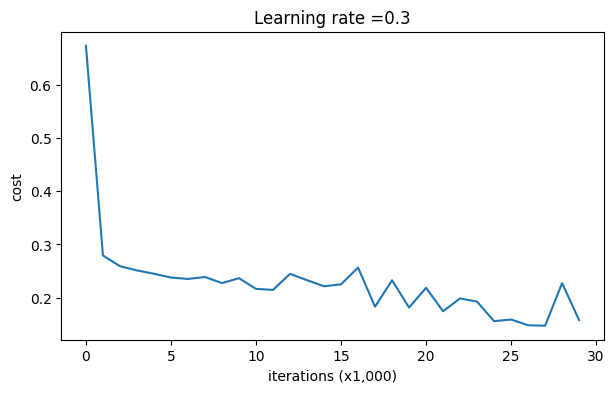

Training accuracy:
Accuracy: 0.9222222222222223
Validation accuracy:
Accuracy: 0.85


In [6]:
parameters = model(train_X, train_Y)
print("Training accuracy:")
predictions_train = predict(train_X, train_Y, parameters)
print("Validation accuracy:")
predictions_val = predict(val_X, val_Y, parameters)

The baseline below is evaluated on the training and validation sets.


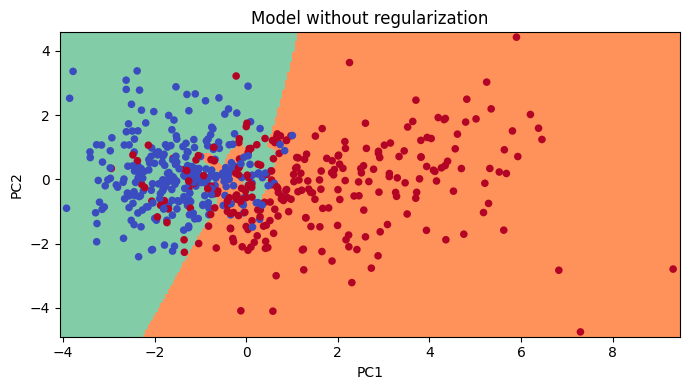

In [7]:
# 2D visualization of seven-dimensional Raisin features using a PCA projection to the fist two principal components.
plt.title("Model without regularization")

plot_decision_boundary_pca(
    parameters,
    train_X,
    train_Y
)


Regularization is evaluated by comparing training and validation accuracy.


<a name='5'></a>
## 5 - L2 Regularization

The standard way to avoid overfitting is called **L2 regularization**. It consists of appropriately modifying your cost function, from:
$$J = -\frac{1}{m} \sum\limits_{i = 1}^{m} \large{(}\small  y^{(i)}\log\left(a^{[L](i)}\right) + (1-y^{(i)})\log\left(1- a^{[L](i)}\right) \large{)} \tag{1}$$
To:
$$J_{regularized} = \small \underbrace{-\frac{1}{m} \sum\limits_{i = 1}^{m} \large{(}\small y^{(i)}\log\left(a^{[L](i)}\right) + (1-y^{(i)})\log\left(1- a^{[L](i)}\right) \large{)} }_\text{cross-entropy cost} + \underbrace{\frac{1}{m} \frac{\lambda}{2} \sum\limits_l\sum\limits_k\sum\limits_j W_{k,j}^{[l]2} }_\text{L2 regularization cost} \tag{2}$$

Let's modify your cost and observe the consequences.

<a name='ex-1'></a>
### Exercise 1 - compute_cost_with_regularization
Implement `compute_cost_with_regularization()` which computes the cost given by formula (2). To calculate $\sum\limits_k\sum\limits_j W_{k,j}^{[l]2}$  , use :
```python
np.sum(np.square(Wl))
```
Note that you have to do this for $W^{[1]}$, $W^{[2]}$ and $W^{[3]}$, then sum the three terms and multiply by $ \frac{1}{m} \frac{\lambda}{2} $.

In [8]:
# GRADED FUNCTION: compute_cost_with_regularization

def compute_cost_with_regularization(A3, Y, parameters, lambd):
    """
    Implement the cost function with L2 regularization. See formula (2) above.

    Arguments:
    A3 -- post-activation, output of forward propagation, of shape (output size, number of examples)
    Y -- "true" labels vector, of shape (output size, number of examples)
    parameters -- python dictionary containing parameters of the model

    Returns:
    cost - value of the regularized loss function (formula (2))
    """
    m = Y.shape[1]
    W1 = parameters["W1"]
    W2 = parameters["W2"]
    W3 = parameters["W3"]

    cross_entropy_cost = compute_cost(A3, Y) # This gives you the cross-entropy part of the cost

    #(≈ 1 lines of code)
    # L2_regularization_cost =
    # YOUR CODE STARTS HERE
    L2_regularization_cost = (np.sum(np.square(W1))+np.sum(np.square(W2))+np.sum(np.square(W3)))*(lambd/(2*m))

    # YOUR CODE ENDS HERE

    cost = cross_entropy_cost + L2_regularization_cost

    return cost

In [9]:
A3, t_Y, parameters = compute_cost_with_regularization_test_case()
cost = compute_cost_with_regularization(A3, t_Y, parameters, lambd=0.1)
print("cost = " + str(cost))

compute_cost_with_regularization_test(compute_cost_with_regularization)

cost = 1.7864859451590758
 All tests passed.


Of course, because you changed the cost, you have to change backward propagation as well! All the gradients have to be computed with respect to this new cost.

<a name='ex-2'></a>
### Exercise 2 - backward_propagation_with_regularization
Implement the changes needed in backward propagation to take into account regularization. The changes only concern dW1, dW2 and dW3. For each, you have to add the regularization term's gradient ($\frac{d}{dW} ( \frac{1}{2}\frac{\lambda}{m}  W^2) = \frac{\lambda}{m} W$).

In [10]:
# GRADED FUNCTION: backward_propagation_with_regularization

def backward_propagation_with_regularization(X, Y, cache, lambd):
    """
    Implements the backward propagation of our baseline model to which we added an L2 regularization.

    Arguments:
    X -- input dataset, of shape (input size, number of examples)
    Y -- "true" labels vector, of shape (output size, number of examples)
    cache -- cache output from forward_propagation()
    lambd -- regularization hyperparameter, scalar

    Returns:
    gradients -- A dictionary with the gradients with respect to each parameter, activation and pre-activation variables
    """

    m = X.shape[1]
    (Z1, A1, W1, b1, Z2, A2, W2, b2, Z3, A3, W3, b3) = cache

    dZ3 = A3 - Y
    #(≈ 1 lines of code)
    # dW3 = 1./m * np.dot(dZ3, A2.T) + None
    # YOUR CODE STARTS HERE
    dW3 = 1./m * np.dot(dZ3, A2.T) + lambd/m*W3

    # YOUR CODE ENDS HERE
    db3 = 1. / m * np.sum(dZ3, axis=1, keepdims=True)

    dA2 = np.dot(W3.T, dZ3)
    dZ2 = np.multiply(dA2, np.int64(A2 > 0))
    #(≈ 1 lines of code)
    # dW2 = 1./m * np.dot(dZ2, A1.T) + None
    # YOUR CODE STARTS HERE
    dW2 = 1./m * np.dot(dZ2, A1.T) + lambd/m*W2

    # YOUR CODE ENDS HERE
    db2 = 1. / m * np.sum(dZ2, axis=1, keepdims=True)

    dA1 = np.dot(W2.T, dZ2)
    dZ1 = np.multiply(dA1, np.int64(A1 > 0))
    #(≈ 1 lines of code)
    # dW1 = 1./m * np.dot(dZ1, X.T) + None
    # YOUR CODE STARTS HERE
    dW1 = 1./m * np.dot(dZ1, X.T) + lambd/m*W1

    # YOUR CODE ENDS HERE
    db1 = 1. / m * np.sum(dZ1, axis=1, keepdims=True)

    gradients = {"dZ3": dZ3, "dW3": dW3, "db3": db3,"dA2": dA2,
                 "dZ2": dZ2, "dW2": dW2, "db2": db2, "dA1": dA1,
                 "dZ1": dZ1, "dW1": dW1, "db1": db1}

    return gradients

In [11]:
t_X, t_Y, cache = backward_propagation_with_regularization_test_case()

grads = backward_propagation_with_regularization(t_X, t_Y, cache, lambd = 0.7)
print ("dW1 = \n"+ str(grads["dW1"]))
print ("dW2 = \n"+ str(grads["dW2"]))
print ("dW3 = \n"+ str(grads["dW3"]))
backward_propagation_with_regularization_test(backward_propagation_with_regularization)

dW1 = 
[[-0.25604646  0.12298827 -0.28297129]
 [-0.17706303  0.34536094 -0.4410571 ]]
dW2 = 
[[ 0.79276486  0.85133918]
 [-0.0957219  -0.01720463]
 [-0.13100772 -0.03750433]]
dW3 = 
[[-1.77691347 -0.11832879 -0.09397446]]
 All tests passed.


Let's now run the model with L2 regularization $(\lambda = 0.7)$. The `model()` function will call:
- `compute_cost_with_regularization` instead of `compute_cost`
- `backward_propagation_with_regularization` instead of `backward_propagation`

Cost after iteration 0: 0.6880897607729417


/content/scripts/reg_utils.py:236: RuntimeWarning: divide by zero encountered in log
  logprobs = np.multiply(-np.log(a3),Y) + np.multiply(-np.log(1 - a3), 1 - Y)
/content/scripts/reg_utils.py:236: RuntimeWarning: invalid value encountered in multiply
  logprobs = np.multiply(-np.log(a3),Y) + np.multiply(-np.log(1 - a3), 1 - Y)


Cost after iteration 10000: 0.28234734134999573
Cost after iteration 20000: 0.28526973731546823


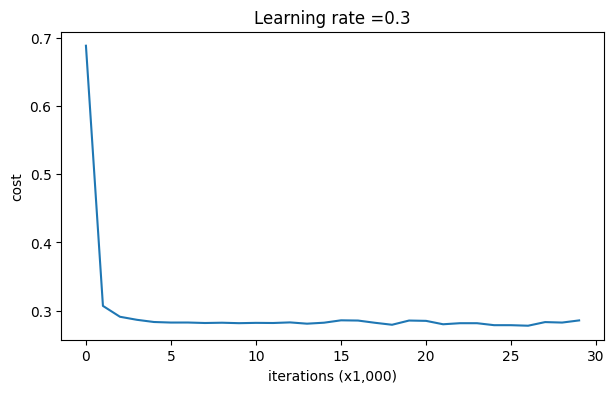

Training accuracy:
Accuracy: 0.8851851851851852
Validation accuracy:
Accuracy: 0.8611111111111112


In [12]:
parameters = model(train_X, train_Y, lambd=0.7)
print("Training accuracy:")
predictions_train = predict(train_X, train_Y, parameters)
print("Validation accuracy:")
predictions_val = predict(val_X, val_Y, parameters)

The L2 result above is specific to the Raisin dataset and must be interpreted after execution.


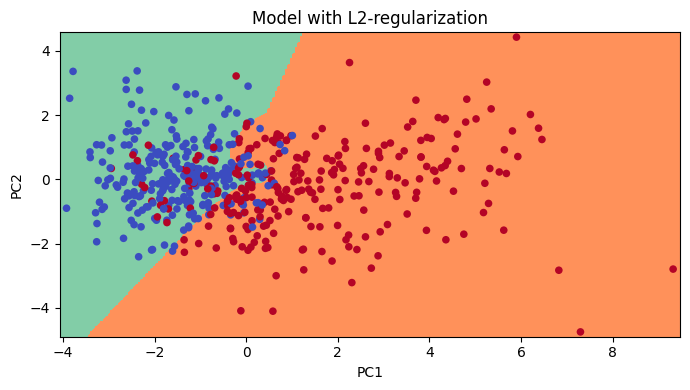

In [13]:
plt.title("Model with L2-regularization")

plot_decision_boundary_pca(
    parameters,
    train_X,
    train_Y
)


L2 strength is selected using validation accuracy.


<a name='6'></a>
## 6 - Dropout

Finally, **dropout** is a widely used regularization technique that is specific to deep learning.
**It randomly shuts down some neurons in each iteration.** Watch these two videos to see what this means!

<!--
To understand drop-out, consider this conversation with a friend:
- Friend: "Why do you need all these neurons to train your network and classify images?".
- You: "Because each neuron contains a weight and can learn specific features/details/shape of an image. The more neurons I have, the more featurse my model learns!"
- Friend: "I see, but are you sure that your neurons are learning different features and not all the same features?"
- You: "Good point... Neurons in the same layer actually don't talk to each other. It should be definitly possible that they learn the same image features/shapes/forms/details... which would be redundant. There should be a solution."
!-->


<center>
<video width="620" height="440" src="images/dropout1_kiank.mp4" type="video/mp4" controls>
</video>
</center>
<br>
<caption><center><font color='purple'><b>Figure 2 </b>: <b>Drop-out on the second hidden layer.</b> <br> At each iteration, you shut down (= set to zero) each neuron of a layer with probability $1 - keep\_prob$ or keep it with probability $keep\_prob$ (50% here). The dropped neurons don't contribute to the training in both the forward and backward propagations of the iteration. </font></center></caption>

<center>
<video width="620" height="440" src="images/dropout2_kiank.mp4" type="video/mp4" controls>
</video>
</center>

<caption><center><font color='purple'><b>Figure 3</b>:<b> Drop-out on the first and third hidden layers. </b><br> $1^{st}$ layer: we shut down on average 40% of the neurons.  $3^{rd}$ layer: we shut down on average 20% of the neurons. </font></center></caption>


When you shut some neurons down, you actually modify your model. The idea behind drop-out is that at each iteration, you train a different model that uses only a subset of your neurons. With dropout, your neurons thus become less sensitive to the activation of one other specific neuron, because that other neuron might be shut down at any time.

<a name='6-1'></a>
### 6.1 - Forward Propagation with Dropout

<a name='ex-3'></a>
### Exercise 3 - forward_propagation_with_dropout

Implement the forward propagation with dropout. You are using a 3 layer neural network, and will add dropout to the first and second hidden layers. We will not apply dropout to the input layer or output layer.

**Instructions**:
You would like to shut down some neurons in the first and second layers. To do that, you are going to carry out 4 Steps:
1. In lecture, we dicussed creating a variable $d^{[1]}$ with the same shape as $a^{[1]}$ using `np.random.rand()` to randomly get numbers between 0 and 1. Here, you will use a vectorized implementation, so create a random matrix $D^{[1]} = [d^{[1](1)} d^{[1](2)} ... d^{[1](m)}] $ of the same dimension as $A^{[1]}$.
2. Set each entry of $D^{[1]}$ to be 1 with probability (`keep_prob`), and 0 otherwise.

**Hint:** Let's say that keep_prob = 0.8, which means that we want to keep about 80% of the neurons and drop out about 20% of them.  We want to generate a vector that has 1's and 0's, where about 80% of them are 1 and about 20% are 0.
This python statement:  
`X = (X < keep_prob).astype(int)`  

is conceptually the same as this if-else statement (for the simple case of a one-dimensional array) :

```
for i,v in enumerate(x):
    if v < keep_prob:
        x[i] = 1
    else: # v >= keep_prob
        x[i] = 0
```
Note that the `X = (X < keep_prob).astype(int)` works with multi-dimensional arrays, and the resulting output preserves the dimensions of the input array.

Also note that without using `.astype(int)`, the result is an array of booleans `True` and `False`, which Python automatically converts to 1 and 0 if we multiply it with numbers.  (However, it's better practice to convert data into the data type that we intend, so try using `.astype(int)`.)

3. Set $A^{[1]}$ to $A^{[1]} * D^{[1]}$. (You are shutting down some neurons). You can think of $D^{[1]}$ as a mask, so that when it is multiplied with another matrix, it shuts down some of the values.
4. Divide $A^{[1]}$ by `keep_prob`. By doing this you are assuring that the result of the cost will still have the same expected value as without drop-out. (This technique is also called inverted dropout.)

In [14]:
# GRADED FUNCTION: forward_propagation_with_dropout

def forward_propagation_with_dropout(X, parameters, keep_prob = 0.5):
    """
    Implements the forward propagation: LINEAR -> RELU + DROPOUT -> LINEAR -> RELU + DROPOUT -> LINEAR -> SIGMOID.

    Arguments:
    X -- input dataset, of shape (2, number of examples)
    parameters -- python dictionary containing your parameters "W1", "b1", "W2", "b2", "W3", "b3":
                    W1 -- weight matrix of shape (20, 2)
                    b1 -- bias vector of shape (20, 1)
                    W2 -- weight matrix of shape (3, 20)
                    b2 -- bias vector of shape (3, 1)
                    W3 -- weight matrix of shape (1, 3)
                    b3 -- bias vector of shape (1, 1)
    keep_prob - probability of keeping a neuron active during drop-out, scalar

    Returns:
    A3 -- last activation value, output of the forward propagation, of shape (1,1)
    cache -- tuple, information stored for computing the backward propagation
    """

    np.random.seed(1)

    # retrieve parameters
    W1 = parameters["W1"]
    b1 = parameters["b1"]
    W2 = parameters["W2"]
    b2 = parameters["b2"]
    W3 = parameters["W3"]
    b3 = parameters["b3"]

    # LINEAR -> RELU -> LINEAR -> RELU -> LINEAR -> SIGMOID
    Z1 = np.dot(W1, X) + b1
    A1 = relu(Z1)
    #(≈ 4 lines of code)         # Steps 1-4 below correspond to the Steps 1-4 described above.
    # D1 =                                           # Step 1: initialize matrix D1 = np.random.rand(..., ...)
    # D1 =                                           # Step 2: convert entries of D1 to 0 or 1 (using keep_prob as the threshold)
    # A1 =                                           # Step 3: shut down some neurons of A1
    # A1 =                                           # Step 4: scale the value of neurons that haven't been shut down
    # YOUR CODE STARTS HERE
    D1 = np.random.rand(A1.shape[0],A1.shape[1])
    D1 = (D1 < keep_prob).astype(int)
    A1 = A1 * D1
    A1 = A1/keep_prob

    # YOUR CODE ENDS HERE
    Z2 = np.dot(W2, A1) + b2
    A2 = relu(Z2)
    #(≈ 4 lines of code)
    # D2 =                                           # Step 1: initialize matrix D2 = np.random.rand(..., ...)
    # D2 =                                           # Step 2: convert entries of D2 to 0 or 1 (using keep_prob as the threshold)
    # A2 =                                           # Step 3: shut down some neurons of A2
    # A2 =                                           # Step 4: scale the value of neurons that haven't been shut down
    # YOUR CODE STARTS HERE
    D2 = np.random.rand(A2.shape[0],A2.shape[1])
    D2 = (D2 < keep_prob).astype(int)
    A2 = A2 * D2
    A2 = A2/keep_prob

    # YOUR CODE ENDS HERE
    Z3 = np.dot(W3, A2) + b3
    A3 = sigmoid(Z3)

    cache = (Z1, D1, A1, W1, b1, Z2, D2, A2, W2, b2, Z3, A3, W3, b3)

    return A3, cache

In [15]:
t_X, parameters = forward_propagation_with_dropout_test_case()

A3, cache = forward_propagation_with_dropout(t_X, parameters, keep_prob=0.7)
print ("A3 = " + str(A3))

forward_propagation_with_dropout_test(forward_propagation_with_dropout)

A3 = [[0.36974721 0.00305176 0.04565099 0.49683389 0.36974721]]
 All tests passed.


<a name='6-2'></a>
### 6.2 - Backward Propagation with Dropout

<a name='ex-4'></a>
### Exercise 4 - backward_propagation_with_dropout
Implement the backward propagation with dropout. As before, you are training a 3 layer network. Add dropout to the first and second hidden layers, using the masks $D^{[1]}$ and $D^{[2]}$ stored in the cache.

**Instruction**:
Backpropagation with dropout is actually quite easy. You will have to carry out 2 Steps:
1. You had previously shut down some neurons during forward propagation, by applying a mask $D^{[1]}$ to `A1`. In backpropagation, you will have to shut down the same neurons, by reapplying the same mask $D^{[1]}$ to `dA1`.
2. During forward propagation, you had divided `A1` by `keep_prob`. In backpropagation, you'll therefore have to divide `dA1` by `keep_prob` again (the calculus interpretation is that if $A^{[1]}$ is scaled by `keep_prob`, then its derivative $dA^{[1]}$ is also scaled by the same `keep_prob`).


In [16]:
# GRADED FUNCTION: backward_propagation_with_dropout

def backward_propagation_with_dropout(X, Y, cache, keep_prob):
    """
    Implements the backward propagation of our baseline model to which we added dropout.

    Arguments:
    X -- input dataset, of shape (2, number of examples)
    Y -- "true" labels vector, of shape (output size, number of examples)
    cache -- cache output from forward_propagation_with_dropout()
    keep_prob - probability of keeping a neuron active during drop-out, scalar

    Returns:
    gradients -- A dictionary with the gradients with respect to each parameter, activation and pre-activation variables
    """

    m = X.shape[1]
    (Z1, D1, A1, W1, b1, Z2, D2, A2, W2, b2, Z3, A3, W3, b3) = cache

    dZ3 = A3 - Y
    dW3 = 1./m * np.dot(dZ3, A2.T)
    db3 = 1./m * np.sum(dZ3, axis=1, keepdims=True)
    dA2 = np.dot(W3.T, dZ3)
    #(≈ 2 lines of code)
    # dA2 =                # Step 1: Apply mask D2 to shut down the same neurons as during the forward propagation
    # dA2 =                # Step 2: Scale the value of neurons that haven't been shut down
    # YOUR CODE STARTS HERE
    dA2 = D2 * dA2
    dA2 = dA2 / keep_prob
    # YOUR CODE ENDS HERE
    dZ2 = np.multiply(dA2, np.int64(A2 > 0))
    dW2 = 1./m * np.dot(dZ2, A1.T)
    db2 = 1./m * np.sum(dZ2, axis=1, keepdims=True)

    dA1 = np.dot(W2.T, dZ2)
    #(≈ 2 lines of code)
    # dA1 =                # Step 1: Apply mask D1 to shut down the same neurons as during the forward propagation
    # dA1 =                # Step 2: Scale the value of neurons that haven't been shut down
    # YOUR CODE STARTS HERE
    dA1 = D1 * dA1
    dA1 = dA1 /keep_prob

    # YOUR CODE ENDS HERE
    dZ1 = np.multiply(dA1, np.int64(A1 > 0))
    dW1 = 1./m * np.dot(dZ1, X.T)
    db1 = 1./m * np.sum(dZ1, axis=1, keepdims=True)

    gradients = {"dZ3": dZ3, "dW3": dW3, "db3": db3,"dA2": dA2,
                 "dZ2": dZ2, "dW2": dW2, "db2": db2, "dA1": dA1,
                 "dZ1": dZ1, "dW1": dW1, "db1": db1}

    return gradients

In [17]:
t_X, t_Y, cache = backward_propagation_with_dropout_test_case()

gradients = backward_propagation_with_dropout(t_X, t_Y, cache, keep_prob=0.8)

print ("dA1 = \n" + str(gradients["dA1"]))
print ("dA2 = \n" + str(gradients["dA2"]))

backward_propagation_with_dropout_test(backward_propagation_with_dropout)

dA1 = 
[[ 0.36544439  0.         -0.00188233  0.         -0.17408748]
 [ 0.65515713  0.         -0.00337459  0.         -0.        ]]
dA2 = 
[[ 0.58180856  0.         -0.00299679  0.         -0.27715731]
 [ 0.          0.53159854 -0.          0.53159854 -0.34089673]
 [ 0.          0.         -0.00292733  0.         -0.        ]]
 All tests passed.


Let's now run the model with dropout (`keep_prob = 0.86`). It means at every iteration you shut down each neurons of layer 1 and 2 with 14% probability. The function `model()` will now call:
- `forward_propagation_with_dropout` instead of `forward_propagation`.
- `backward_propagation_with_dropout` instead of `backward_propagation`.

Cost after iteration 0: 0.6748253943219064


/content/scripts/reg_utils.py:236: RuntimeWarning: divide by zero encountered in log
  logprobs = np.multiply(-np.log(a3),Y) + np.multiply(-np.log(1 - a3), 1 - Y)
/content/scripts/reg_utils.py:236: RuntimeWarning: invalid value encountered in multiply
  logprobs = np.multiply(-np.log(a3),Y) + np.multiply(-np.log(1 - a3), 1 - Y)


Cost after iteration 10000: 0.14866288109201972
Cost after iteration 20000: 0.14016340981729292


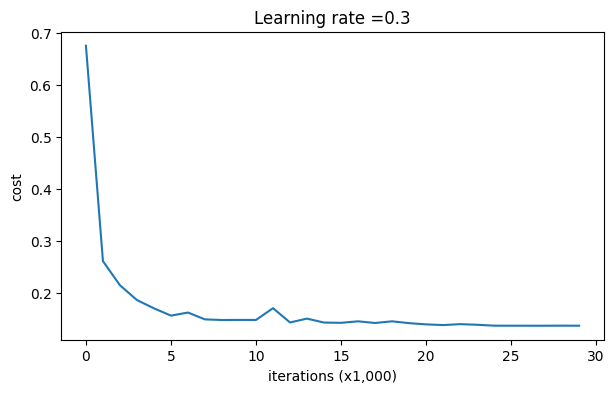

Training accuracy:
Accuracy: 0.8703703703703703
Validation accuracy:
Accuracy: 0.8777777777777778


In [18]:
parameters = model(train_X, train_Y, keep_prob=0.86, learning_rate=0.3)
print("Training accuracy:")
predictions_train = predict(train_X, train_Y, parameters)
print("Validation accuracy:")
predictions_val = predict(val_X, val_Y, parameters)

The dropout result above is specific to the Raisin dataset and must be interpreted after execution.


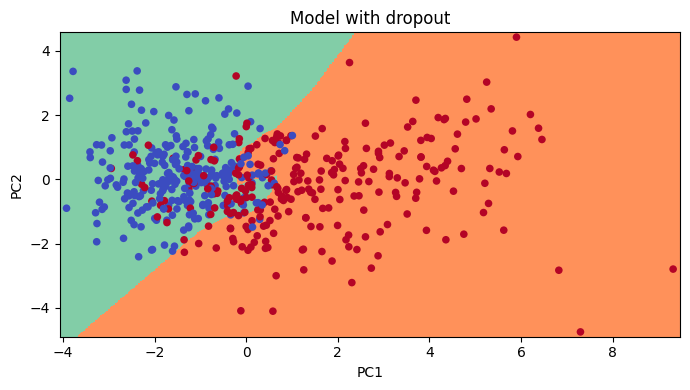

In [19]:
plt.title("Model with dropout")

plot_decision_boundary_pca(
    parameters,
    train_X,
    train_Y
)

**Note**:
- A **common mistake** when using dropout is to use it both in training and testing. You should use dropout (randomly eliminate nodes) only in training.
- Deep learning frameworks like [tensorflow](https://www.tensorflow.org/api_docs/python/tf/nn/dropout), [PaddlePaddle](http://doc.paddlepaddle.org/release_doc/0.9.0/doc/ui/api/trainer_config_helpers/attrs.html), [keras](https://keras.io/layers/core/#dropout) or [caffe](http://caffe.berkeleyvision.org/tutorial/layers/dropout.html) come with a dropout layer implementation. Don't stress - you will soon learn some of these frameworks.

<font color='blue'>
    
**What you should remember about dropout:**
- Dropout is a regularization technique.
- You only use dropout during training. Don't use dropout (randomly eliminate nodes) during test time.
- Apply dropout both during forward and backward propagation.
- During training time, divide each dropout layer by keep_prob to keep the same expected value for the activations. For example, if keep_prob is 0.5, then we will on average shut down half the nodes, so the output will be scaled by 0.5 since only the remaining half are contributing to the solution. Dividing by 0.5 is equivalent to multiplying by 2. Hence, the output now has the same expected value. You can check that this works even when keep_prob is other values than 0.5.  

---
## 7 - Experiments: baseline, L1, L2, dropout, and augmentation

All runs below use the original **7–20–3–1** network, the same initialization (`seed=3`), the same learning rate (0.3), and **5,000 iterations**. The examples above remain unchanged as a tutorial; these runs make the comparison fair. Only training and validation accuracy are reported during model selection.

In [20]:
import pandas as pd

SEED = 3
ITERATIONS = 5000
LEARNING_RATE = 0.3

# L1: cross entropy + (lambda/m) * sum of absolute weights.
def compute_cost_with_l1(A3, Y, parameters, lambd):
    m = Y.shape[1]
    penalty = sum(np.abs(parameters[f"W{l}"]).sum() for l in (1, 2, 3))
    return compute_cost(A3, Y) + lambd * penalty / m


def backward_propagation_with_l1(X, Y, cache, lambd):
    grads = backward_propagation(X, Y, cache)
    m = Y.shape[1]
    for l, W in zip((1, 2, 3), (cache[2], cache[6], cache[10])):
        grads[f"dW{l}"] += (lambd / m) * np.sign(W)
    return grads

### 7.1 - Shared training and evaluation

We reuse the original forward propagation, backward propagation, and parameter updates. Dropout uses a new random mask at each iteration (inverted dropout). Results are deterministic between runs because the initialization and random generator are fixed.

In [21]:
def forward_dropout_random(X, parameters, keep_prob, rng):
    W1, b1 = parameters["W1"], parameters["b1"]
    W2, b2 = parameters["W2"], parameters["b2"]
    W3, b3 = parameters["W3"], parameters["b3"]

    Z1 = W1 @ X + b1
    A1 = relu(Z1)
    D1 = (rng.random(A1.shape) < keep_prob)
    A1 = A1 * D1 / keep_prob
    Z2 = W2 @ A1 + b2
    A2 = relu(Z2)
    D2 = (rng.random(A2.shape) < keep_prob)
    A2 = A2 * D2 / keep_prob
    Z3 = W3 @ A2 + b3
    A3 = sigmoid(Z3)
    return A3, (Z1, D1, A1, W1, b1, Z2, D2, A2, W2, b2, Z3, A3, W3, b3)


def accuracy(X, Y, parameters):
    A3, _ = forward_propagation(X, parameters)  # dropout OFF during evaluation
    return 100 * np.mean((A3 >= 0.5) == Y)


def augment_training(X, Y, sigma=0.05, copies=1, seed=SEED):
    # Features are standardized; Gaussian jitter is generated only for train.
    rng = np.random.default_rng(seed + 100)
    xs = [X] + [X + rng.normal(0, sigma, X.shape) for _ in range(copies)]
    ys = [Y] * (copies + 1)
    return np.concatenate(xs, axis=1), np.concatenate(ys, axis=1)


def run_experiment(name, technique='baseline', value=0.0):
    X, Y = train_X, train_Y
    if technique == 'augmentation':
        X, Y = augment_training(train_X, train_Y, sigma=value)

    parameters = initialize_parameters([X.shape[0], 20, 3, 1])  # original seed=3
    rng = np.random.default_rng(SEED + 1000)
    for _ in range(ITERATIONS):
        if technique == 'dropout':
            _, cache = forward_dropout_random(X, parameters, value, rng)
            grads = backward_propagation_with_dropout(X, Y, cache, value)
        else:
            _, cache = forward_propagation(X, parameters)
            if technique == 'l2':
                grads = backward_propagation_with_regularization(X, Y, cache, value)
            elif technique == 'l1':
                grads = backward_propagation_with_l1(X, Y, cache, value)
            else:
                grads = backward_propagation(X, Y, cache)
        parameters = update_parameters(parameters, grads, LEARNING_RATE)

    result = {'Method': name, 'Technique': technique, 'Value': value,
              'Train accuracy (%)': accuracy(train_X, train_Y, parameters),
              'Validation accuracy (%)': accuracy(val_X, val_Y, parameters)}
    return result, parameters


def display_results(rows):
    return pd.DataFrame(rows).round(2)

### 7.2 - Baseline and L2 (Ridge)

L2 penalizes large weights through $\frac{\lambda}{2m}\sum_l \|W_l\|_F^2$. Test several values of $\lambda$ and compare both accuracies against the baseline.

In [22]:
results = []
models = {}

configurations = [('Baseline', 'baseline', 0.0)] + [
    (f'L2 (lambda={lam:g})', 'l2', lam)
    for lam in (0.01, 0.1, 0.7, 2.0)
]
for name, technique, value in configurations:
    metrics, params = run_experiment(name, technique, value)
    results.append(metrics)
    models[name] = params

display(display_results(results))

,Method,Technique,Value,Train accuracy (%),Validation accuracy (%)
0,Baseline,baseline,0.00,90.37,86.67
1,L2 (lambda=0.01),l2,0.01,90.56,86.11
2,L2 (lambda=0.1),l2,0.10,89.63,85.00
3,L2 (lambda=0.7),l2,0.70,89.26,85.56
4,L2 (lambda=2),l2,2.00,88.70,86.11


### 7.3 - L1 (Lasso)

L1 penalizes the absolute weights with $\frac{\lambda}{m}\sum_l\|W_l\|_1$. We add its gradient term $\frac{\lambda}{m}\operatorname{sign}(W_l)$ only to the weight gradients, not the biases.

In [23]:
for lam in (0.01, 0.1, 0.7, 2.0):
    name = f'L1 (lambda={lam:g})'
    metrics, params = run_experiment(name, 'l1', lam)
    results.append(metrics)
    models[name] = params

display(display_results([r for r in results if r['Technique'] == 'l1']))

,Method,Technique,Value,Train accuracy (%),Validation accuracy (%)
0,L1 (lambda=0.01),l1,0.01,90.74,86.11
1,L1 (lambda=0.1),l1,0.10,89.26,86.67
2,L1 (lambda=0.7),l1,0.70,89.44,87.22
3,L1 (lambda=2),l1,2.00,86.30,86.67


### 7.4 - Dropout

`keep_prob` is the probability of retaining a hidden unit, so the dropout rate is the complement. Training uses a new mask on each iteration; evaluation does not apply dropout.

In [24]:
for keep_prob in (0.95, 0.86, 0.7, 0.5):
    name = f'Dropout (keep_prob={keep_prob:g})'
    metrics, params = run_experiment(name, 'dropout', keep_prob)
    results.append(metrics)
    models[name] = params

display(display_results([r for r in results if r['Technique'] == 'dropout']))

,Method,Technique,Value,Train accuracy (%),Validation accuracy (%)
0,Dropout (keep_prob=0.95),dropout,0.95,90.93,86.11
1,Dropout (keep_prob=0.86),dropout,0.86,89.26,86.11
2,Dropout (keep_prob=0.7),dropout,0.70,88.33,86.11
3,Dropout (keep_prob=0.5),dropout,0.50,87.96,86.67


## 8 - Comparison and final evaluation

The following table and plot directly shows a regularization benchmark between each technique and hyperparameter.

,Method,Technique,Value,Train accuracy (%),Validation accuracy (%),Train-validation gap (pp)
0,Baseline,baseline,0.00,90.37,86.67,3.70
1,L2 (lambda=0.01),l2,0.01,90.56,86.11,4.45
2,L2 (lambda=0.1),l2,0.10,89.63,85.00,4.63
3,L2 (lambda=0.7),l2,0.70,89.26,85.56,3.70
4,L2 (lambda=2),l2,2.00,88.70,86.11,2.59
5,L1 (lambda=0.01),l1,0.01,90.74,86.11,4.63
6,L1 (lambda=0.1),l1,0.10,89.26,86.67,2.59
7,L1 (lambda=0.7),l1,0.70,89.44,87.22,2.22
8,L1 (lambda=2),l1,2.00,86.30,86.67,-0.37
9,Dropout (keep_prob=0.95),dropout,0.95,90.93,86.11,4.82


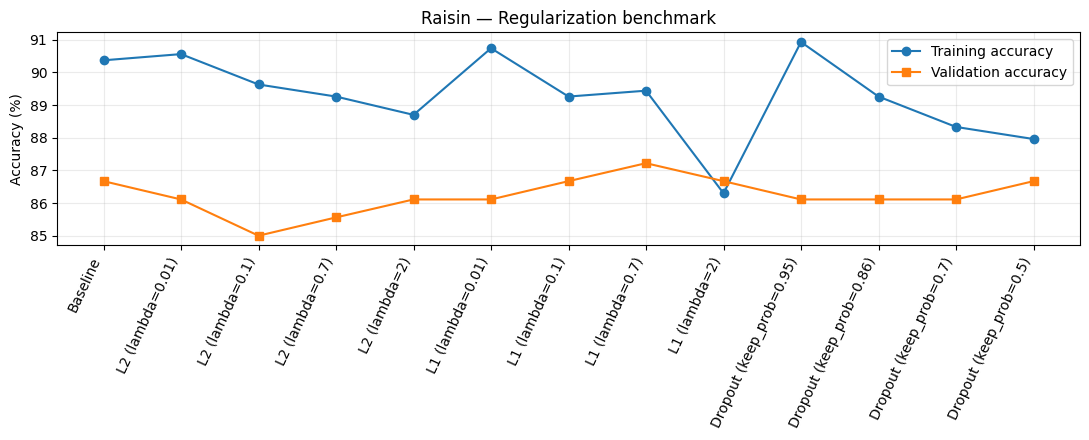

In [27]:
summary = display_results(results)
summary['Train-validation gap (pp)'] = (
    summary['Train accuracy (%)'] - summary['Validation accuracy (%)']
).round(2)
display(summary)

fig, ax = plt.subplots(figsize=(11, 4.5))
positions = np.arange(len(summary))
ax.plot(positions, summary['Train accuracy (%)'], 'o-', label='Training accuracy')
ax.plot(positions, summary['Validation accuracy (%)'], 's-', label='Validation accuracy')
ax.set_xticks(positions, summary['Method'], rotation=65, ha='right')
ax.set_ylabel('Accuracy (%)')
ax.set_title('Raisin — Regularization benchmark')
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

In [29]:
# Select using validation only
best_idx = int(np.argmax([r['Validation accuracy (%)'] for r in results]))
best = results[best_idx]
best_params = models[best['Method']]
print('Selected:', best['Method'])
print(f"Training accuracy:   {best['Train accuracy (%)']:.2f}%")
print(f"Validation accuracy: {best['Validation accuracy (%)']:.2f}%")
print(f"Held-out test accuracy: {accuracy(test_X, test_Y, best_params):.2f}%")

Selected: L1 (lambda=0.7)
Training accuracy:   89.44%
Validation accuracy: 87.22%
Held-out test accuracy: 88.33%
